# Toy model: a simple cycle with an escape

This notebook reproduces the analysis of the toy model of the [MaBoSS website](https://maboss.curie.fr).

The model consists of three nodes: A, B and C. A is activated by C and inhibited by B, B is activated by A,
and C can only be degraded, when both A and B are inactive. The transition graph shows a fixed point
[ABC] = [000], and a cycle [101] → [111] → [011] → [001]. At [001], the system can either continue to cycle,
or escape the cycle and reach the fixed point [000]. We explore the dynamics when this escape rate
(the degradation of C) is fast or slow.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `Four_cycle.bnd`,
`Four_cycle_FEscape.cfg`, `Four_cycle_SEscape.cfg` and `Four_cycle_SEscape_long.cfg`, in the same folder as this notebook.

In [1]:
import os
import maboss
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Common style for the figures of the MaBoSS website notebooks
COLORS = ["#FF7F00", "#1F77B4", "#2CA02C", "#D62728", "#9467BD",
          "#8C564B", "#E377C2", "#17BECF", "#BCBD22", "#7F7F7F"]
mpl.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.prop_cycle": mpl.cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    """Save a figure in the figures folder."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))

def state_label(state):
    """Readable label for a MaBoSS state."""
    return "none active" if state == "<nil>" else state.replace(" -- ", ", ")

def pie(probas, ax, title=None, min_proba=0.01, labels=None):
    """Pie chart of a distribution; probabilities below min_proba are grouped as 'others'."""
    probas = pd.Series(probas).sort_values(ascending=False)
    small = probas[probas < min_proba]
    probas = probas[probas >= min_proba]
    if len(small) > 0:
        probas["others"] = small.sum()
    names = [labels.get(s, state_label(s)) if labels else state_label(s) for s in probas.index]
    colors = [COLORS[i % len(COLORS)] if s != "others" else "#D9D9D9" for i, s in enumerate(probas.index)]
    wedges, _ = ax.pie(probas.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{n} ({p:.1%})" for n, p in zip(names, probas.values)],
              loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)

def set_refstate_all(sim, value=0):
    """Give a reference state to every node.

    With MaBoSS 2.6.6, the states of the stationary distributions only include the nodes
    having a reference state; this makes them include all the nodes, as in previous versions.
    """
    for node in sim.network:
        if node not in sim.refstate:
            sim.refstate[node] = value

ipylab module is not installed, menus and toolbar are disabled.


## The model

The rates of the transitions are given by the parameters `$Au`, `$Ad` and `$escape`, defined in the configuration files.
The parameter `$escape` corresponds to the degradation of C: it is set to 10 in the fast case, and to 0.00001 in the slow case.
All the nodes are initially active.

In [2]:
fast = maboss.load("Four_cycle.bnd", "Four_cycle_FEscape.cfg")
fast.print_bnd()

Node C {


	rate_up = 0.0;
	rate_down = ((NOT A) AND (NOT B)) ? $escape : 0.0 ;
}
Node A {


	rate_up = (C AND (NOT B))  ? $Au : 0.0;
	rate_down = B ? $Ad : 0.0;
}

Node B {


	rate_up = A ? $Au : 0.0;
	rate_down = A ? 0.0 : $Ad ;
}


## Simulations

We run three simulations: the fast escape, the slow escape, and the slow escape over a much longer time
(this last one takes a few minutes).

In [3]:
slow = maboss.load("Four_cycle.bnd", "Four_cycle_SEscape.cfg")
slow_long = maboss.load("Four_cycle.bnd", "Four_cycle_SEscape_long.cfg")

results = {
    "fast": fast.run(),
    "slow": slow.run(),
    "slow_long": slow_long.run(),
}

## Results

For each simulation, we plot the probability of the states [1\*\*] (A is active) and [000] (the fixed point),
as well as the entropy (H) and the transition entropy (TH), as functions of time.

In [4]:
def plot_toy(result, title):
    states = result.get_states_probtraj()
    nodes = result.get_nodes_probtraj()
    entropy = result.get_entropy_trajectory()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 5.5), sharex=True)
    ax1.plot(nodes.index, nodes["A"], label="[ABC] = [1**]")
    ax1.plot(states.index, states["<nil>"], label="[ABC] = [000]")
    ax1.set_ylabel("Probability")
    ax1.set_ylim(-0.02, 1.02)
    ax1.legend(loc="center right")
    ax1.set_title(title)

    ax2.plot(entropy.index, entropy["TH"], label="Transition entropy (TH)")
    ax2.plot(entropy.index, entropy["H"], label="Entropy (H)")
    ax2.set_ylabel("Entropy")
    ax2.set_xlabel("Time")
    ax2.legend(loc="center right")
    fig.tight_layout()
    return fig

### Fast escape

The probability to reach the fixed point tends to 1, and both the entropy and the transition entropy tend to 0.

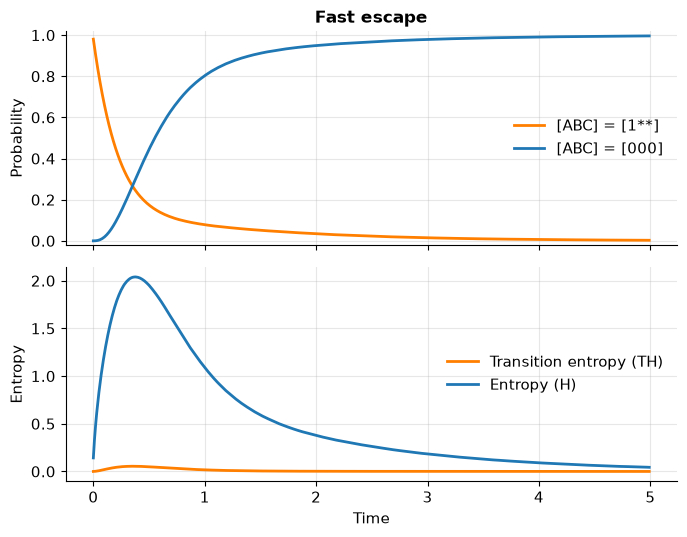

In [5]:
fig = plot_toy(results["fast"], "Fast escape")
save(fig, "toy_fast_escape")

### Slow escape

When looking at the early response, the probabilities do not show the presence of the fixed point:
the system seems stuck in a limit cycle.

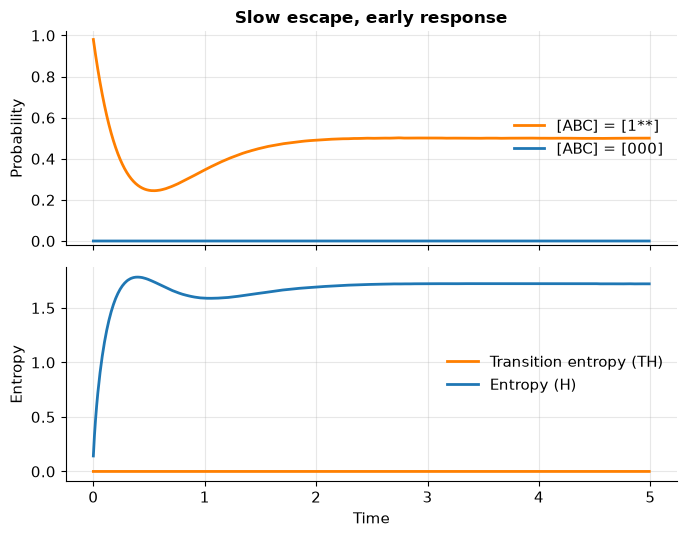

In [6]:
fig = plot_toy(results["slow"], "Slow escape, early response")
save(fig, "toy_slow_escape")

It is only after a long time that the system reaches the fixed point, and that the entropy and transition
entropy reach 0. The two simulations show both the transient and the asymptotic behaviours.

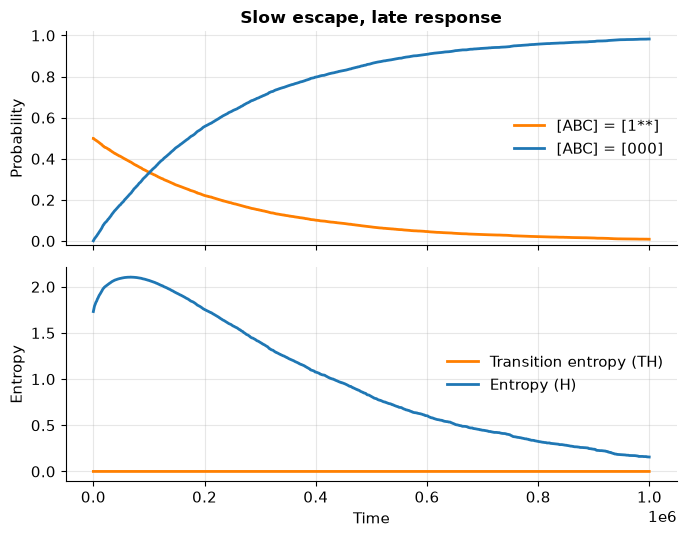

In [7]:
fig = plot_toy(results["slow_long"], "Slow escape, late response")
save(fig, "toy_slow_escape_long")